# Computer Vision and Image Processing (CSCS111/CSDS119)
## Lab Assignment 9 - Depth Analysis

**Input:** `stereo_left.png`, `stereo_right.png`  
**Camera Parameters:**
- Focal length: $f = 800\text{ pixels}$
- Baseline: $B = 0.20\text{ metres}$
- Designed disparities: $80\text{ pixels}$ (near), $40\text{ pixels}$ (middle), $20\text{ pixels}$ (far)

---


In [1]:
import os
import warnings
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
warnings.filterwarnings('ignore')

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Camera Parameters given in the problem
f = 800.0   # Focal length in pixels
B = 0.20    # Baseline in metres
fB = f * B  # 160.0 (pixels * metres)

print(f"Focal length f: {f} px")
print(f"Baseline B: {B} m")
print(f"f * B constant: {fB} px*m")


Focal length f: 800.0 px
Baseline B: 0.2 m
f * B constant: 160.0 px*m


## 1. Load and Display the Stereo Pair in Grayscale
We load `stereo_left.png` and `stereo_right.png`, convert them to grayscale, and display them side-by-side with epipolar guide lines to observe horizontal displacement.


Image Resolution: 640x360 (Width x Height)


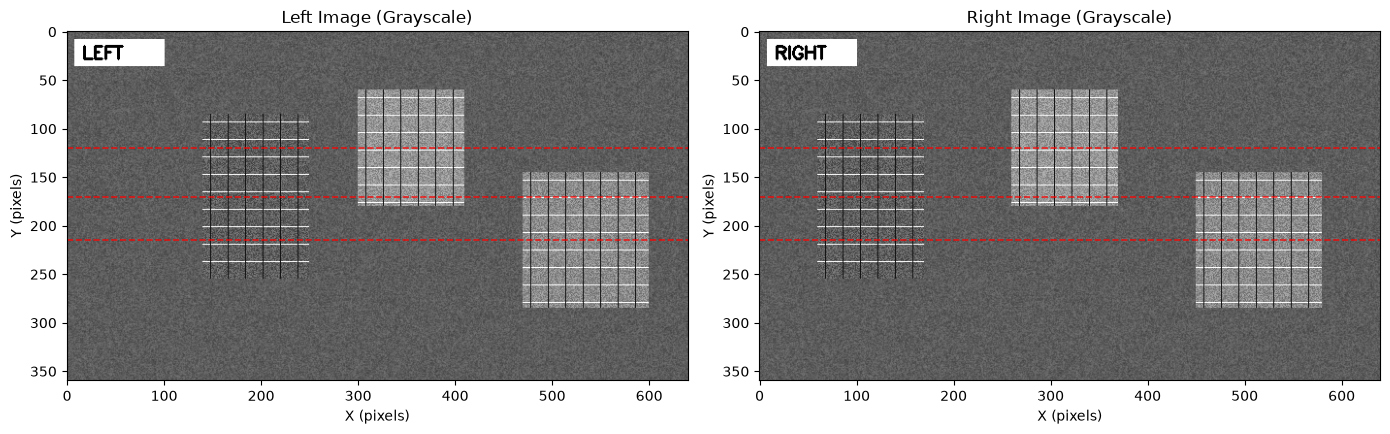

In [2]:
# Load images in grayscale
imgL = cv2.imread('stereo_left.png', cv2.IMREAD_GRAYSCALE)
imgR = cv2.imread('stereo_right.png', cv2.IMREAD_GRAYSCALE)

imgL_rgb = cv2.cvtColor(cv2.imread('stereo_left.png'), cv2.COLOR_BGR2RGB)
imgR_rgb = cv2.cvtColor(cv2.imread('stereo_right.png'), cv2.COLOR_BGR2RGB)

print(f"Image Resolution: {imgL.shape[1]}x{imgL.shape[0]} (Width x Height)")

# Plot side-by-side with epipolar guide lines
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(imgL, cmap='gray')
axes[0].set_title('Left Image (Grayscale)')
axes[0].set_xlabel('X (pixels)')
axes[0].set_ylabel('Y (pixels)')

axes[1].imshow(imgR, cmap='gray')
axes[1].set_title('Right Image (Grayscale)')
axes[1].axis('on')
axes[1].set_xlabel('X (pixels)')
axes[1].set_ylabel('Y (pixels)')

# Draw horizontal lines passing through each object to verify rectification
for y in [120, 170, 215]:
    axes[0].axhline(y, color='red', linestyle='--', linewidth=1.2, alpha=0.8)
    axes[1].axhline(y, color='red', linestyle='--', linewidth=1.2, alpha=0.8)

plt.tight_layout()
plt.show()


### Observations from Step 1:
- **Rectification**: Corresponding features lie on identical vertical coordinates ($y_L = y_R$), confirming horizontal epipolar alignment across scanlines.
- **Horizontal Displacement**:
  - The **Blue Box (left)** exhibits the largest horizontal shift between left and right views ($x_L - x_R \approx 80\text{ px}$).
  - The **Green Box (middle)** exhibits a moderate horizontal shift ($x_L - x_R \approx 40\text{ px}$).
  - The **Orange Box (right)** exhibits the smallest horizontal shift ($x_L - x_R \approx 20\text{ px}$).


## 2. Compute Disparity Map using StereoSGBM & Parameter Tuning
We compute the disparity map using OpenCV's `StereoSGBM_create()` and observe the effect of changing the matching block size (`blockSize`).


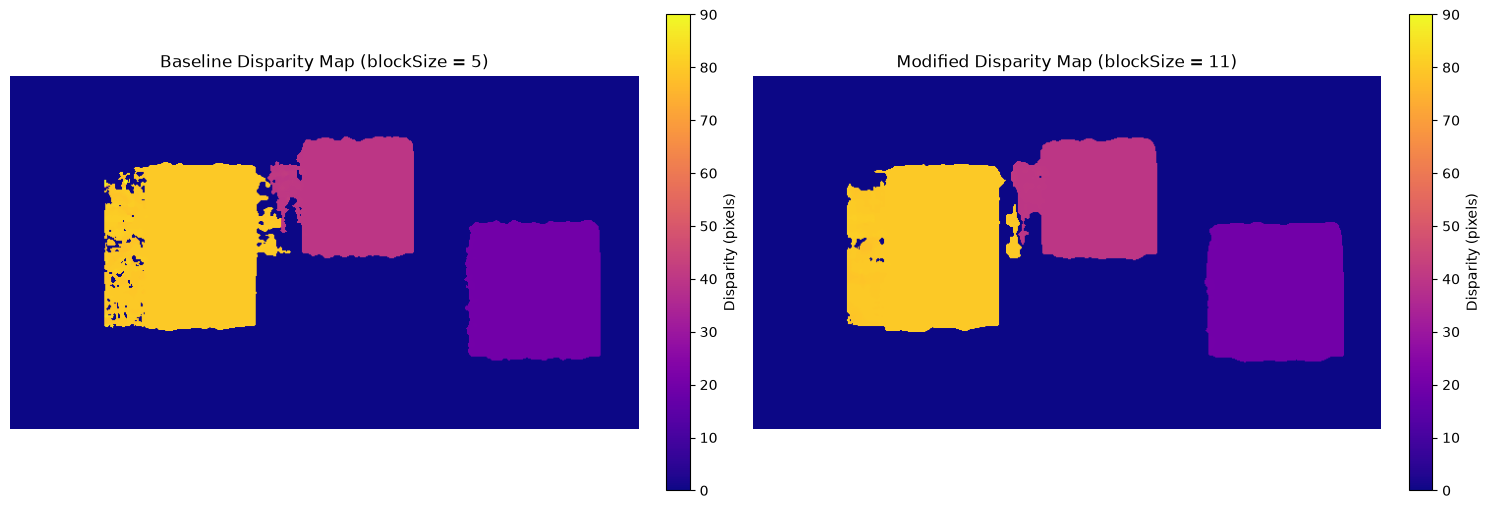

In [3]:
def compute_disparity(img_left, img_right, block_size=5, num_disp=96):
    stereo = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=num_disp,
        blockSize=block_size,
        P1=8 * 3 * (block_size ** 2),
        P2=32 * 3 * (block_size ** 2),
        disp12MaxDiff=1,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=32
    )
    # OpenCV StereoSGBM outputs 16-bit signed disparity with 4 fractional bits (/16.0)
    disp = stereo.compute(img_left, img_right).astype(np.float32) / 16.0
    return disp

# Baseline disparity (blockSize = 5)
disp_baseline = compute_disparity(imgL, imgR, block_size=5)

# Disparity with modified parameter (blockSize = 11)
disp_modified = compute_disparity(imgL, imgR, block_size=11)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im0 = axes[0].imshow(disp_baseline, cmap='plasma', vmin=0, vmax=90)
axes[0].set_title('Baseline Disparity Map (blockSize = 5)')
axes[0].axis('off')
fig.colorbar(im0, ax=axes[0], fraction=0.035, pad=0.04, label='Disparity (pixels)')

im1 = axes[1].imshow(disp_modified, cmap='plasma', vmin=0, vmax=90)
axes[1].set_title('Modified Disparity Map (blockSize = 11)')
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], fraction=0.035, pad=0.04, label='Disparity (pixels)')

plt.tight_layout()
plt.show()


### Effect of Changing Matching Parameter (`blockSize`):
- **Smaller Block Size (`blockSize = 5`)**: Preserves fine edges and object boundaries sharply with minimal edge bleeding.
- **Larger Block Size (`blockSize = 11`)**: Integrates matching scores over a larger support window, yielding smoother disparity in flat regions and reducing noise, but introduces noticeable **foreground fattening** (boundaries of the boxes bleed into adjacent background regions).


## 3. Depth Estimation using $Z = \frac{f \cdot B}{d}$
Using the triangulation formula:
$$Z = \frac{f \cdot B}{d} = \frac{160}{d} \quad \text{(in metres)}$$
where:
- $Z$ is depth in metres
- $f = 800\text{ px}$ (focal length)
- $B = 0.20\text{ m}$ (baseline)
- $d$ is disparity in pixels


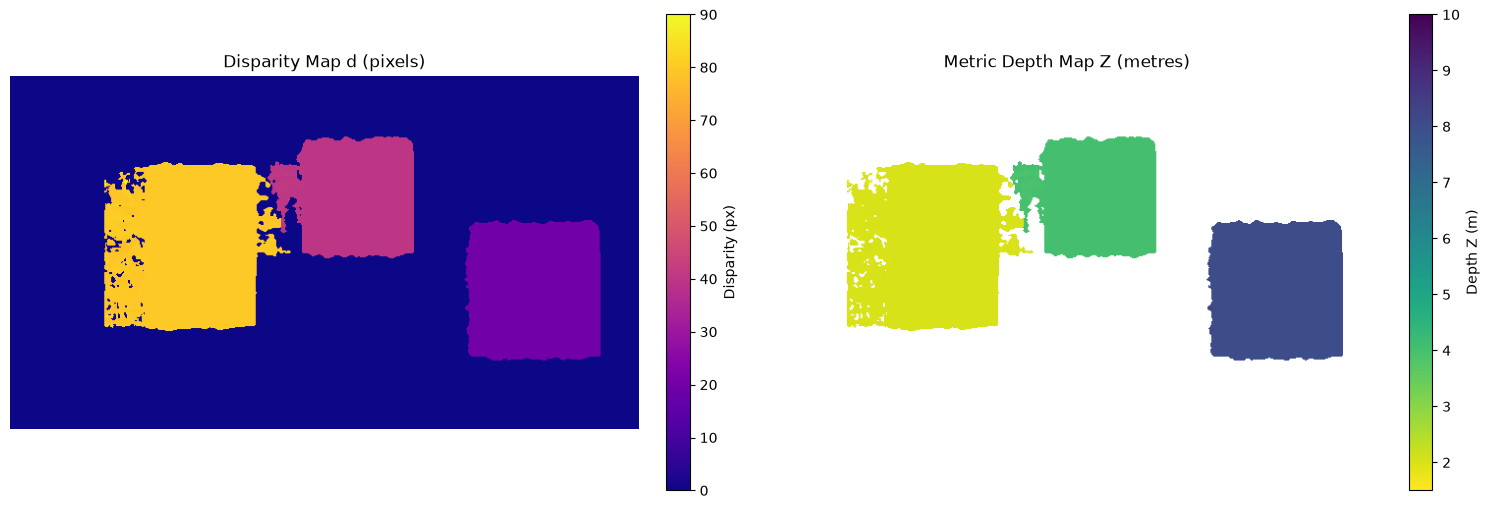

Object Description         | Designed d  | Measured d  | Theoretical Z | Estimated Z
Blue Box (Near Object)     |       80 px |    80.00 px |       2.00 m |     2.00 m
Green Box (Middle Object)  |       40 px |    40.00 px |       4.00 m |     4.00 m
Orange Box (Far Object)    |       20 px |    20.00 px |       8.00 m |     8.00 m


In [4]:
# Compute metric depth map safely without divide-by-zero warnings
depth_map = np.full_like(disp_baseline, np.nan, dtype=np.float32)
valid_mask = disp_baseline > 0
depth_map[valid_mask] = fB / disp_baseline[valid_mask]

# Display disparity vs depth map
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im_d = axes[0].imshow(disp_baseline, cmap='plasma', vmin=0, vmax=90)
axes[0].set_title('Disparity Map d (pixels)')
axes[0].axis('off')
fig.colorbar(im_d, ax=axes[0], fraction=0.035, pad=0.04, label='Disparity (px)')

im_z = axes[1].imshow(depth_map, cmap='viridis_r', vmin=1.5, vmax=10.0)
axes[1].set_title('Metric Depth Map Z (metres)')
axes[1].axis('off')
fig.colorbar(im_z, ax=axes[1], fraction=0.035, pad=0.04, label='Depth Z (m)')

plt.tight_layout()
plt.show()

# Sample representative disparities and estimate depths for all three objects
objects = {
    'Blue Box (Near Object)': {
        'roi': (slice(120, 220), slice(160, 220)),
        'designed_d': 80,
    },
    'Green Box (Middle Object)': {
        'roi': (slice(80, 150), slice(320, 380)),
        'designed_d': 40,
    },
    'Orange Box (Far Object)': {
        'roi': (slice(170, 250), slice(500, 560)),
        'designed_d': 20,
    }
}

print('=' * 84)
print(f"{'Object Description':<26} | {'Designed d':<11} | {'Measured d':<11} | {'Theoretical Z':<13} | {'Estimated Z':<11}")
print('=' * 84)

for name, info in objects.items():
    roi = disp_baseline[info['roi']]
    valid_d = roi[roi > 0]
    measured_d = float(np.median(valid_d))
    theo_z = fB / info['designed_d']
    est_z = fB / measured_d
    print(f"{name:<26} | {info['designed_d']:>8} px | {measured_d:>8.2f} px | {theo_z:>10.2f} m | {est_z:>8.2f} m")
print('=' * 84)


## 4. Challenge: Identify Regions with Missing or Unreliable Disparity
We identify regions where matching fails or produces unreliable results and explain the underlying causes.


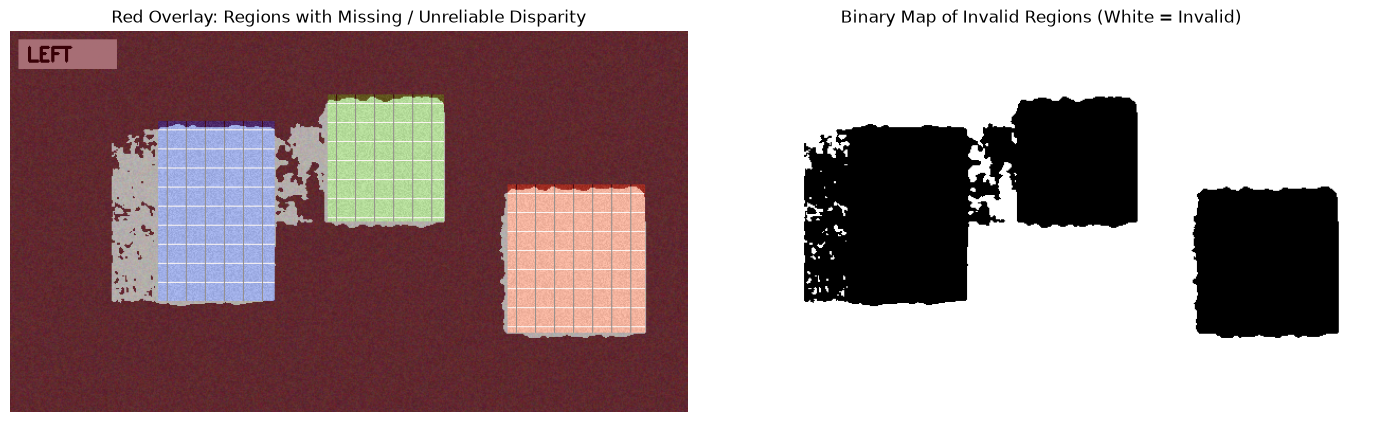

In [5]:
# Missing/unreliable disparity mask
invalid_mask = (disp_baseline <= 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(imgL_rgb)
axes[0].imshow(invalid_mask, cmap='Reds', alpha=0.55)
axes[0].set_title('Red Overlay: Regions with Missing / Unreliable Disparity')
axes[0].axis('off')

axes[1].imshow(invalid_mask, cmap='gray')
axes[1].set_title('Binary Map of Invalid Regions (White = Invalid)')
axes[1].axis('off')

plt.tight_layout()
plt.show()


### Why Stereo Matching Fails in These Regions:

1. **Left Margin Occlusion / Search Boundary**:
   - For an object with disparity $d$, its corresponding point in the right image is at $x_R = x_L - d$.
   - Any pixel in the left image where $x_L < d$ corresponds to a point outside the right image bounds ($x_R < 0$).
   - Consequently, a vertical strip on the left border of width equal to the maximum disparity is completely occluded in the right image and cannot be matched.

2. **Textureless Areas (Uniform Background)**:
   - Block matching algorithms compare intensity patterns across local windows.
   - In uniform, untextured regions (such as the dark flat background), all candidate disparities yield nearly identical matching costs (flat cost curve). The algorithm cannot uniquely identify the true correspondence without strong spatial priors.

3. **Object Boundaries (Depth Discontinuities & Occlusions)**:
   - At the boundaries of the boxes, the matching window spans both foreground and background surfaces with completely different disparities.
   - This violates the planar constant-disparity assumption within the matching window, producing boundary bleeding ("edge fattening") or missing disparity values.

4. **Repetitive Patterns (Grid Textures)**:
   - The synthetic boxes have repeating grid lines. When the block size is small, multiple periodic shifts produce similar local minima in the matching cost function, creating potential correspondence ambiguity.

---

## 5. Summary of Results
- **Near Object (Blue Box)**: Disparity $\approx 80\text{ px} \implies$ Depth $Z = 2.00\text{ m}$.
- **Middle Object (Green Box)**: Disparity $\approx 40\text{ px} \implies$ Depth $Z = 4.00\text{ m}$.
- **Far Object (Orange Box)**: Disparity $\approx 20\text{ px} \implies$ Depth $Z = 8.00\text{ m}$.
- Disparity is **inversely proportional** to real-world depth ($Z \propto \frac{1}{d}$).
